# 결함 형태 근사 복원 & 시각화

- **데이터**: `data/steel_plates_faults.csv` (원본)
- **목적**: 분류 성능이 아니라 **시각화**. 결함 클래스별로 "대략 이런 모양"을 눈으로 비교한다.
- **사용 변수 (7개)**: 위치 4개(`X_Minimum`, `X_Maximum`, `Y_Minimum`, `Y_Maximum`), 크기·형태 3개(`Pixels_Areas`, `X_Perimeter`, `Y_Perimeter`)

> 이 그림은 실제 결함 모양이 아니다. 아래 **조건을 만족하는 모양 중 하나**를 규칙에 따라 고른 것이다.

## 전제 조건 → 구현 방법

| 조건 | 구현 |
|---|---|
| 결함은 bounding box 네 변에 모두 닿는다 | 중심 행·열은 항상 박스 끝까지 채움 |
| 넓이 = `Pixels_Areas` | superellipse `|u|^p + |v|^p ≤ 1`의 지수 `p`로 조절 (p 작음 → 별 모양 / 2 → 타원 / 큼 → 사각형) |
| `X_Perimeter` = 가로 방향 경계 길이(위·아래 평균) | 좌우 경계를 위아래 방향으로 출렁이게 해서 가로 경계를 늘림 |
| `Y_Perimeter` = 세로 방향 경계 길이(좌·우 평균) | 상하 경계를 좌우 방향으로 출렁이게 해서 세로 경계를 늘림 |
| 가장 덜 꼬불꼬불하게 | 출렁임 횟수 `k`를 **1부터** 늘려 가며, 목표 둘레에 도달하는 가장 작은 `k` 사용 |
| 점대칭 | 상하·좌우 대칭 함수만 사용 → 자동으로 점대칭 |
| 한 덩어리 | 중심과 연결된 영역만 남김 |

## 크기가 큰 결함 처리

모든 결함을 **긴 변 96px 캔버스로 정규화**한다 (가로세로 비율 유지, 짧은 변은 최소 16px).
채움 비율·둘레 비율은 크기와 무관한 비율이라 정규화해도 의미가 유지된다. 그래서 결함이 아무리 커도 그리는 시간은 같다 (샘플당 약 0.03초).
실제 크기는 그림 제목에 따로 표시한다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

## 1. 데이터 로드 & 형태 변수 계산

In [2]:
raw = pd.read_csv("data/steel_plates_faults.csv")
FAULTS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains", "Dirtiness", "Bumps", "Other_Faults"]

shape = pd.DataFrame({
    "W":    raw["X_Maximum"] - raw["X_Minimum"],
    "H":    raw["Y_Maximum"] - raw["Y_Minimum"],
    "area": raw["Pixels_Areas"],
    "px":   raw["X_Perimeter"],
    "py":   raw["Y_Perimeter"],
    "Fault": raw[FAULTS].idxmax(axis=1),
})
shape["fill"] = shape["area"] / (shape["W"] * shape["H"])   # 박스를 얼마나 채우는지
shape["rx"]   = shape["px"] / shape["W"]                     # 가로 꼬불거림 (1 = 직선)
shape["ry"]   = shape["py"] / shape["H"]                     # 세로 꼬불거림 (1 = 직선)

shape.groupby("Fault")[["W", "H", "fill", "rx", "ry"]].median().round(2)

,W,H,fill,rx,ry
Fault,,,,,
Bumps,12.5,14.0,0.67,1.38,1.00
Dirtiness,10.0,35.0,0.60,3.44,1.00
K_Scatch,155.0,67.0,0.54,1.62,2.11
Other_Faults,14.0,18.0,0.58,1.55,1.07
Pastry,10.0,30.5,0.68,2.00,1.00
Stains,6.0,4.0,0.59,1.00,1.00
Z_Scratch,15.0,20.0,0.54,2.00,1.07


## 2. 복원 함수

- `render`: 파라미터 → 0/1 마스크
- `measure`: 마스크 → (넓이, 가로 둘레, 세로 둘레). 이웃 픽셀 값이 바뀌는 경계를 세서 계산
- `fit_shape`: 목표 넓이·둘레에 맞는 파라미터를 이분 탐색으로 찾음. 둘레와 넓이가 서로 영향을 주므로 번갈아 3번 맞춘다.

In [3]:
CANVAS = 96      # 긴 변 픽셀 수
MIN_SIDE = 16    # 짧은 변 최소 픽셀 수 (너무 가는 결함도 모양이 보이도록)
N_ITER = 3       # 둘레 ↔ 넓이 번갈아 맞추는 횟수


def canvas_size(W, H):
    s = CANVAS / max(W, H)
    return max(MIN_SIDE, round(W * s)), max(MIN_SIDE, round(H * s))


def bump(t, k):
    # 중심(t=0)에서 0, 바깥으로 갈수록 k번 출렁이는 0~1 함수 (짝함수 → 대칭 유지)
    return (1 - np.cos(k * np.pi * t)) / 2


def render(w, h, p, ax, kx, ay, ky):
    u = (np.arange(w) + 0.5) / w * 2 - 1
    v = (np.arange(h) + 0.5) / h * 2 - 1
    U, V = np.meshgrid(u, v)
    base = np.abs(U) ** p + np.abs(V) ** p <= 1     # 넓이 담당
    half_w = 1 - ax * bump(V, kx)                   # 좌우 경계 출렁임 → 가로 둘레 증가
    half_h = 1 - ay * bump(U, ky)                   # 상하 경계 출렁임 → 세로 둘레 증가
    m = base & (np.abs(U) <= half_w) & (np.abs(V) <= half_h)
    lab, _ = ndimage.label(m)                       # 중심과 연결된 한 덩어리만 남김
    return lab == lab[h // 2, w // 2]


def measure(m):
    pad = np.pad(m.astype(int), 1)
    lh = np.abs(np.diff(pad, axis=0)).sum()   # 가로 경계 길이 (위+아래)
    lv = np.abs(np.diff(pad, axis=1)).sum()   # 세로 경계 길이 (좌+우)
    return m.sum(), lh / 2, lv / 2            # 평균 → X_Perimeter, Y_Perimeter 정의와 동일


def bisect(f, lo, hi, target, n=18):
    # f가 단조증가라고 가정한 이분 탐색
    for _ in range(n):
        mid = (lo + hi) / 2
        if f(mid) < target:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2


def fit_shape(W, H, area, px, py, max_amp=0.8, max_k=30):
    w, h = canvas_size(W, H)
    t_fill = area / (W * H)
    t_px = min(px / W, w / 2) * w      # 캔버스 해상도로 표현 가능한 만큼만
    t_py = min(py / H, h / 2) * h
    prm = dict(p=2.0, ax=0.0, kx=1, ay=0.0, ky=1)

    for _ in range(N_ITER):
        # 1) 둘레: 출렁임 횟수 k를 1부터 늘려 가며 목표에 닿는 가장 작은 k 사용 (= 가장 덜 꼬불꼬불)
        for amp, k, idx, target in (("ax", "kx", 1, t_px), ("ay", "ky", 2, t_py)):
            for kk in range(1, max_k + 1):
                g = lambda a: measure(render(w, h, **{**prm, amp: a, k: kk}))[idx]
                if g(max_amp) >= target or kk == max_k:
                    prm[k] = kk
                    prm[amp] = bisect(g, 0, max_amp, target, 12)
                    break
        # 2) 넓이: superellipse 지수 p (마지막에 맞춰서 넓이 오차를 가장 작게)
        f = lambda lp: render(w, h, **{**prm, "p": np.exp(lp)}).sum()
        prm["p"] = np.exp(bisect(f, np.log(0.15), np.log(30), t_fill * w * h))

    m = render(w, h, **prm)
    a, mx, my = measure(m)
    fit = {"fill": (t_fill, a / (w * h)), "rx": (px / W, mx / w), "ry": (py / H, my / h)}
    return m, prm, fit

## 3. 샘플 하나로 확인 — 목표 vs 복원 결과

Pastry  /  원래 크기 8 x 44  /  캔버스 17 x 96
파라미터: {'p': 30.0, 'ax': 0.53, 'kx': 2.0, 'ay': 0.0, 'ky': 1.0}
                fill     rx   ry
target         0.759  2.125  1.0
reconstructed  0.735  2.176  1.0


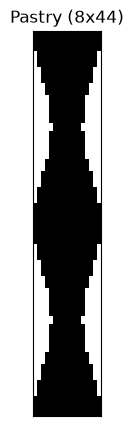

In [4]:
r = shape.iloc[0]
m, prm, fit = fit_shape(r.W, r.H, r.area, r.px, r.py)

print(f"{r.Fault}  /  원래 크기 {r.W} x {r.H}  /  캔버스 {m.shape[1]} x {m.shape[0]}")
print("파라미터:", {k: round(float(v), 3) for k, v in prm.items()})
print(pd.DataFrame(fit, index=["target", "reconstructed"]).round(3))

plt.figure(figsize=(3, 5))
plt.imshow(m, cmap="gray_r")
plt.title(f"{r.Fault} ({r.W}x{r.H})")
plt.xticks([]); plt.yticks([])
plt.show()

## 4. 클래스별 샘플 갤러리

클래스마다 무작위 6개. 제목: 실제 크기(W×H), fill / rx / ry 목표값.

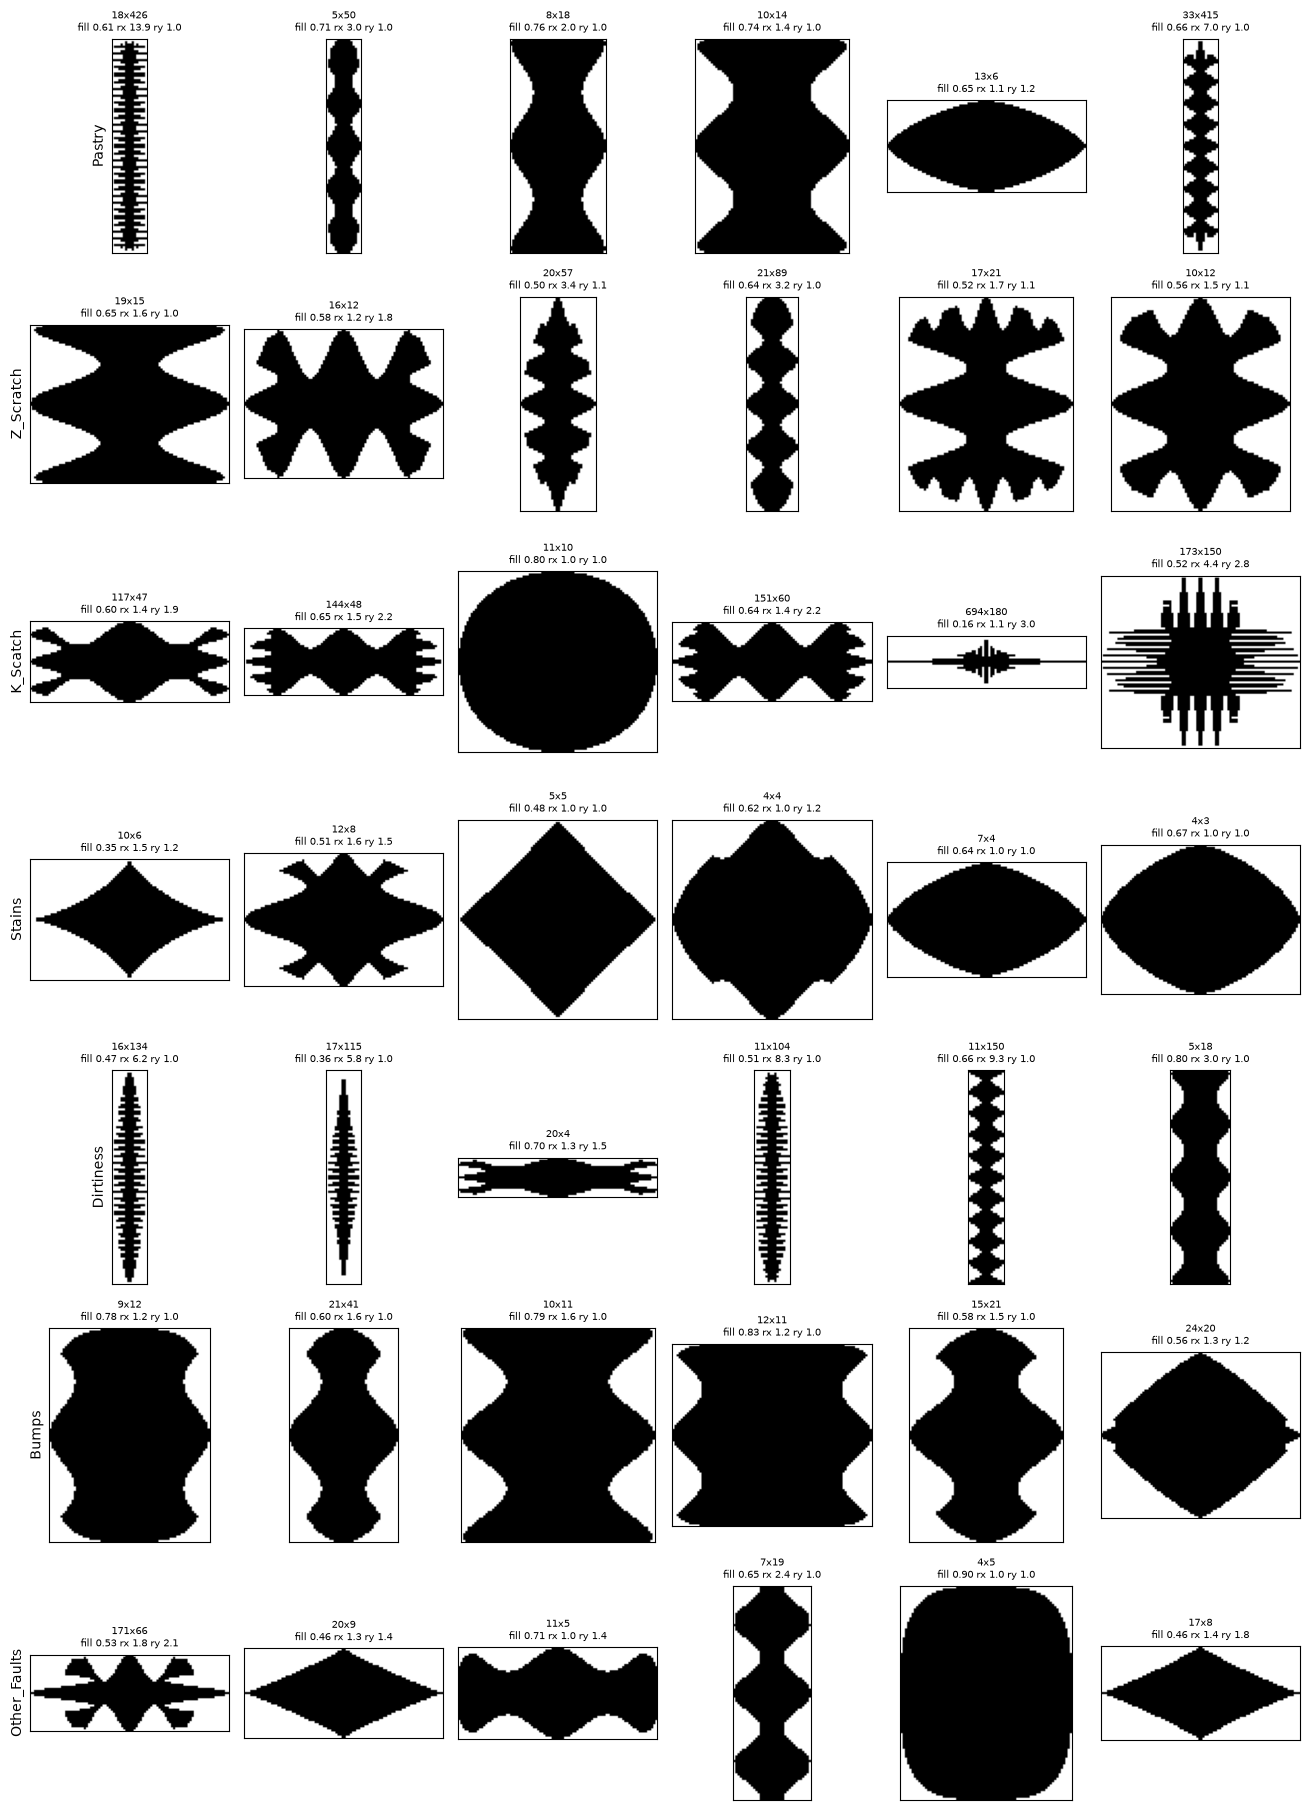

In [5]:
N_PER_CLASS = 6
samples = shape.groupby("Fault").sample(N_PER_CLASS, random_state=0)

fig, axes = plt.subplots(len(FAULTS), N_PER_CLASS, figsize=(2.2 * N_PER_CLASS, 2.6 * len(FAULTS)))
for row, fault in enumerate(FAULTS):
    for col, (_, r) in enumerate(samples[samples["Fault"] == fault].iterrows()):
        m, _, _ = fit_shape(r.W, r.H, r.area, r.px, r.py)
        ax = axes[row, col]
        ax.imshow(m, cmap="gray_r")
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{r.W}x{r.H}\nfill {r.fill:.2f} rx {r.rx:.1f} ry {r.ry:.1f}", fontsize=7)
        if col == 0:
            ax.set_ylabel(fault, fontsize=10)
plt.tight_layout()
plt.show()

## 5. 클래스 대표 모양

클래스별로 **가로세로 비율·fill·rx·ry의 중앙값**을 가진 가상의 결함을 만들어 그린다. 클래스 간 차이를 한눈에 비교하기 좋다.
(크기는 정규화되므로 넓이 100×100 기준으로 만든다.)

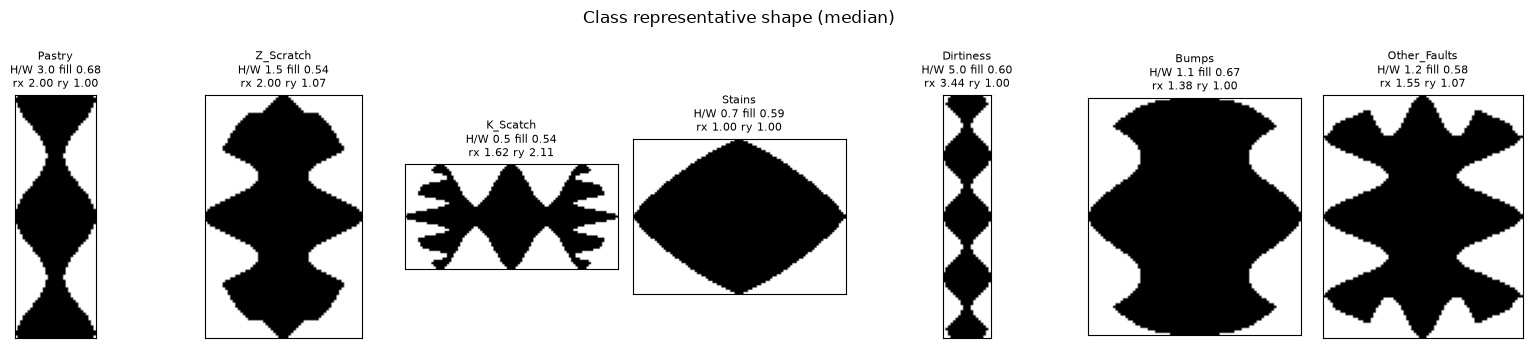

In [6]:
rep = shape.assign(log_aspect=np.log(shape["H"] / shape["W"])) \
           .groupby("Fault")[["log_aspect", "fill", "rx", "ry"]].median().loc[FAULTS]

fig, axes = plt.subplots(1, len(FAULTS), figsize=(2.3 * len(FAULTS), 3.5))
for ax, (fault, r) in zip(axes, rep.iterrows()):
    aspect = np.exp(r.log_aspect)                 # H / W
    W, H = 100 / np.sqrt(aspect), 100 * np.sqrt(aspect)
    m, _, _ = fit_shape(W, H, r.fill * W * H, r.rx * W, r.ry * H)
    ax.imshow(m, cmap="gray_r")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{fault}\nH/W {aspect:.1f} fill {r.fill:.2f}\nrx {r.rx:.2f} ry {r.ry:.2f}", fontsize=8)
plt.suptitle("Class representative shape (median)")
plt.tight_layout()
plt.show()

## 6. 복원 정확도 점검 (전체 데이터)

목표값과 복원값의 차이. 전체 1,941개를 복원하므로 1분 정도 걸린다.

- **fill**은 마지막에 맞추므로 대부분 정확하다.
- **rx / ry**는 출렁임 폭에 상한(`max_amp`)이 있고 캔버스 해상도도 한정돼 있어서, 아주 가늘고 꼬불꼬불한 결함은 목표에 못 미칠 수 있다.

In [7]:
rows = []
for _, r in shape.iterrows():
    _, _, fit = fit_shape(r.W, r.H, r.area, r.px, r.py)
    rows.append({k + "_err": abs(t - got) for k, (t, got) in fit.items()} | {"Fault": r.Fault})
fit_err = pd.DataFrame(rows)

print(fit_err.drop(columns="Fault").describe(percentiles=[0.5, 0.9]).round(3))
fit_err.groupby("Fault").median().round(3)

       fill_err    rx_err    ry_err
count  1941.000  1941.000  1941.000
mean      0.035     0.474     0.134
std       0.068     1.710     0.393
min       0.000     0.000     0.000
50%       0.001     0.243     0.017
90%       0.123     0.949     0.417
max       0.400    69.160    12.417


,fill_err,rx_err,ry_err
Fault,,,
Bumps,0.000,0.250,0.000
Dirtiness,0.002,0.379,0.000
K_Scatch,0.045,0.202,0.077
Other_Faults,0.001,0.250,0.025
Pastry,0.010,0.266,0.000
Stains,0.000,0.042,0.000
Z_Scratch,0.001,0.374,0.033
